In [7]:
import pandas as pd
import xgboost as xgb
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, roc_curve, mean_squared_error
import matplotlib.pyplot as plt
import seaborn as sns
import optuna

df = pd.read_csv('../data/processed/dataset_80_20_normalized_tcr_with_cohort.csv')

In [8]:
df.columns

Index(['Cancer_Type', 'gene', 'Peptide', 'wt_seq', 'pep_mut_start',
       'mutant_best_alleles', 'mutant_rank', 'mutant_rank_netMHCpan',
       'mutant_rank_PRIME', 'mut_Rank_Stab', 'TAP_score',
       'mut_netchop_score_ct', 'mut_binding_score', 'mut_is_binding_pos',
       'DAI_NetMHC', 'DAI_MixMHC', 'DAI_NetStab', 'DAI_MixMHC_mbp',
       'GTEx_all_tissues_expression_mean', 'Sample_Tissue_expression_GTEx',
       'TCGA_Cancer_expression', 'bestWTMatchType_I', 'seq_len',
       'immunogenicity', 'foreignness_score', 'hydrophobicity_avg_diff',
       'hydrophobicity_total_diff', 'mut_Thalf', 'mw_tcr_contact',
       'hydroph_tcr_contact', 'charge_tcr_contact'],
      dtype='object')

In [9]:
#Variable independiente es immunogenicity y me quedo solo con las variables numericas
X = df.select_dtypes(include=['float64', 'int64']).drop(columns=['immunogenicity','mut_is_binding_pos','bestWTMatchType_I','DAI_MixMHC_mbp','mutant_rank'])
#Test reducción dimensionalidad

y = df['immunogenicity']

In [10]:
import os

# Crear carpeta para el conjunto de validación
validation_folder = '../data/validation'
os.makedirs(validation_folder, exist_ok=True)

# Primero separar el 20% para validación final (que no se usará en entrenamiento)
X_temp, X_validation, y_temp, y_validation = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Luego del 80% restante, separar en entrenamiento y test (para desarrollo)
X_train, X_test, y_train, y_test = train_test_split(
    X_temp, y_temp, test_size=0.15, random_state=42, stratify=y_temp
)  # 0.25 * 0.8 = 0.2 del total

# Crear DataFrames completos para guardar
validation_df = pd.DataFrame(X_validation)
validation_df['immunogenicity'] = y_validation.values
validation_df['Peptide'] = df.loc[X_validation.index, 'Peptide']  # Recuperar péptidos

# Guardar los conjuntos
validation_df.to_csv(f'{validation_folder}/validation_dataset.csv', index=False)

In [11]:

def optimizar_xgboost(X, y, n_trials=150):
    def objective(trial):
        params = {
            'scale_pos_weight': trial.suggest_float('scale_pos_weight', 1, 15),
            'max_depth': trial.suggest_int('max_depth', 3, 10),
            'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.3),
            'n_estimators': trial.suggest_int('n_estimators', 50, 300),
            'min_child_weight': trial.suggest_int('min_child_weight', 1, 10),
            'gamma': trial.suggest_float('gamma', 0, 5),
            'subsample': trial.suggest_float('subsample', 0.6, 1.0),
            'colsample_bytree': trial.suggest_float('colsample_bytree', 0.6, 1.0),
            'reg_alpha': trial.suggest_float('reg_alpha', 0, 10),
            'reg_lambda': trial.suggest_float('reg_lambda', 1, 10),
            'eval_metric': 'logloss',
            'random_state': 42
        }
        
        model = xgb.XGBClassifier(**params)
        score = cross_val_score(model, X, y, cv=5, scoring='roc_auc').mean()
        return score

    study = optuna.create_study(direction='maximize')
    study.optimize(objective, n_trials=n_trials)
    
    # Guardar en el mismo formato que tu código original
    guardar_resultado_optuna('XGBoost', study.best_value, study.best_params)
    
    return study.best_params, study.best_value

def guardar_resultado_optuna(model_name, result, best_params, filename='../results/reports/Optuna_Results/optuna_results_general.csv'):
    nuevo_resultado = {
        'model': model_name,
        'result': result,
        'best_params': str(best_params)
    }
    
    try:
        df = pd.read_csv(filename)
        df = pd.concat([df, pd.DataFrame([nuevo_resultado])], ignore_index=True)
    except FileNotFoundError:
        df = pd.DataFrame([nuevo_resultado])
    
    df.to_csv(filename, index=False)
    print(f"✅ Resultado guardado: {model_name} - AUC: {result:.4f}")
    
import ast

def cargar_y_entrenar_mejor_xgb(X_train, y_train, filename='../results/reports/Optuna_Results/optuna_results_general.csv'):
    df = pd.read_csv(filename)
    
    # Buscar el mejor resultado de XGBoost
    xgb_results = df[df['model'] == 'XGBoost'].copy()
    xgb_results = xgb_results.sort_values('result', ascending=False)
    best_xgb_result = xgb_results.iloc[0]
    
    print(f"Mejor resultado de XGBoost: {best_xgb_result['result']}")
    print(f"Parámetros: {best_xgb_result['best_params']}")
    
    # Convertir string a diccionario
    best_params = ast.literal_eval(best_xgb_result['best_params'])
    
    # Crear modelo con los mejores parámetros
    model = xgb.XGBClassifier(**best_params)
    
    print("Entrenando XGBoost con los mejores parámetros...")
    model.fit(X_train, y_train)
    print("¡Modelo entrenado exitosamente!")
    
    return model

In [12]:
best_params, best_score = optimizar_xgboost(X_train, y_train, n_trials=50)
print(f"Mejores parámetros: {best_params}")
print(f"Mejor AUC: {best_score:.4f}")



[I 2025-12-03 11:44:06,004] A new study created in memory with name: no-name-42bba973-6802-4373-be6a-dad9bccfecd2
[I 2025-12-03 11:44:10,348] Trial 0 finished with value: 0.7251861984413835 and parameters: {'scale_pos_weight': 5.428151496544839, 'max_depth': 3, 'learning_rate': 0.0149838174908721, 'n_estimators': 262, 'min_child_weight': 4, 'gamma': 2.169277333836633, 'subsample': 0.7201886231726738, 'colsample_bytree': 0.6226265032940332, 'reg_alpha': 1.454204016677646, 'reg_lambda': 7.4441722062653986}. Best is trial 0 with value: 0.7251861984413835.
[I 2025-12-03 11:44:10,738] Trial 1 finished with value: 0.7938474488081054 and parameters: {'scale_pos_weight': 10.822398614575865, 'max_depth': 3, 'learning_rate': 0.20165125763166736, 'n_estimators': 80, 'min_child_weight': 10, 'gamma': 4.3614995488355754, 'subsample': 0.9047855584864113, 'colsample_bytree': 0.9076707242986584, 'reg_alpha': 5.987683383033416, 'reg_lambda': 1.7723214923100852}. Best is trial 1 with value: 0.79384744880

✅ Resultado guardado: XGBoost - AUC: 0.8331
Mejores parámetros: {'scale_pos_weight': 14.534356532595408, 'max_depth': 5, 'learning_rate': 0.21887291102679035, 'n_estimators': 279, 'min_child_weight': 2, 'gamma': 1.6915431783520947, 'subsample': 0.9186147799199829, 'colsample_bytree': 0.947977663608156, 'reg_alpha': 1.9283834025454185, 'reg_lambda': 9.977399517468161}
Mejor AUC: 0.8331


In [13]:
# Entrenar el modelo
model = cargar_y_entrenar_mejor_xgb(X_train, y_train)

Mejor resultado de XGBoost: 0.847240893550738
Parámetros: {'scale_pos_weight': 10.504734244559945, 'max_depth': 5, 'learning_rate': 0.08748983752477484, 'n_estimators': 251, 'min_child_weight': 4, 'gamma': 0.602097622644281, 'subsample': 0.9277971234210214, 'colsample_bytree': 0.8507163409914319, 'reg_alpha': 9.143180997999554, 'reg_lambda': 5.595089276922523}
Entrenando XGBoost con los mejores parámetros...
¡Modelo entrenado exitosamente!


In [14]:
# Hacer predicciones quiero ver el auc_roc y la matriz de confusion 
y_pred = model.predict(X_test)
# Calcular el error cuadrático medio
mse = mean_squared_error(y_test, y_pred)
print(f'Error Cuadrático Medio: {mse}')

Error Cuadrático Medio: 0.3052866716306776


In [15]:
#Auc-Roc
y_pred_proba = model.predict_proba(X_test)[:, 1]
auc_roc = roc_auc_score(y_test, y_pred_proba)
print(f'AUC-ROC: {auc_roc}')

AUC-ROC: 0.8512933835954765


In [16]:
#Classification Report
print(classification_report(y_test, y_pred))
# Matriz de confusión
cm = confusion_matrix(y_test, y_pred)
print(cm)

              precision    recall  f1-score   support

           0       0.94      0.64      0.76      1029
           1       0.43      0.88      0.57       314

    accuracy                           0.69      1343
   macro avg       0.68      0.76      0.67      1343
weighted avg       0.82      0.69      0.72      1343

[[658 371]
 [ 39 275]]


### FR median

In [17]:
# FR median
def fr_median(y_true, y_scores):
    thresholds = [0.1, 0.2, 0.3, 0.4, 0.5]
    fr_values = []
    for threshold in thresholds:
        y_pred = (y_scores >= threshold).astype(int)
        tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
        fr = fn / (fn + tp) if (fn + tp) > 0 else 0
        fr_values.append(fr)
    return sum(fr_values) / len(fr_values)
fr_median_value = fr_median(y_test, y_pred_proba)
print(f'FR Median: {fr_median_value}')

FR Median: 0.05222929936305733


In [18]:
import numpy as np
import pandas as pd
from sklearn.metrics import precision_recall_curve, auc

# ==========================================================
#  Funciones métricas estilo NeoRanking
# ==========================================================

def fraction_ranked(y_true, y_scores):
    """
    Fraction Ranked (FR): proporción de inmunogénicos (y_true==1)
    que tienen un score válido (no NaN).
    """
    y_true = np.array(y_true)
    y_scores = np.array(y_scores)
    positives = y_true == 1
    if positives.sum() == 0:
        return np.nan
    ranked = ~np.isnan(y_scores[positives])
    return ranked.sum() / positives.sum()

def top_n_recall(y_true, y_scores, n=20):
    """
    Porcentaje de inmunogénicos (positivos) que están en el top-N
    según el score del modelo.
    """
    df = pd.DataFrame({'y_true': y_true, 'y_score': y_scores})
    df = df.sort_values('y_score', ascending=False).reset_index(drop=True)
    top_n = df.head(n)
    if df['y_true'].sum() == 0:
        return np.nan
    return top_n['y_true'].sum() / df['y_true'].sum()

def ttif(y_true, y_scores, n=20):
    """
    Top-N Immunogenic Fraction (TTIF): fracción del top-N
    que realmente es inmunogénico.
    """
    df = pd.DataFrame({'y_true': y_true, 'y_score': y_scores})
    df = df.sort_values('y_score', ascending=False).reset_index(drop=True)
    top_n = df.head(n)
    return top_n['y_true'].sum() / len(top_n)

# ==========================================================
# 📊 Calcular métricas
# ==========================================================

# Fraction Ranked
fr_value = fraction_ranked(y_test, y_pred_proba)

# TTIF y Top-N Recall
ttif_20 = ttif(y_test, y_pred_proba, n=20)
recall_20 = top_n_recall(y_test, y_pred_proba, n=20)
recall_50 = top_n_recall(y_test, y_pred_proba, n=50)
recall_100 = top_n_recall(y_test, y_pred_proba, n=100)

# AUPRC (por si quieres tenerlo junto)
precision, recall, _ = precision_recall_curve(y_test, y_pred_proba)
auprc = auc(recall, precision)

# ==========================================================
# Mostrar resultados
# ==========================================================
print("===== Métricas estilo NeoRanking =====")
print(f"Fraction Ranked (FR): {fr_value:.3f}")
print(f"Top-20 Immunogenic Fraction (TTIF): {ttif_20:.3f}")
print(f"Top-20 Recall: {recall_20:.3f}")
print(f"Top-50 Recall: {recall_50:.3f}")
print(f"Top-100 Recall: {recall_100:.3f}")
print(f"AUPRC: {auprc:.3f}")


===== Métricas estilo NeoRanking =====
Fraction Ranked (FR): 1.000
Top-20 Immunogenic Fraction (TTIF): 0.850
Top-20 Recall: 0.054
Top-50 Recall: 0.121
Top-100 Recall: 0.239
AUPRC: 0.623


### Check feature importance

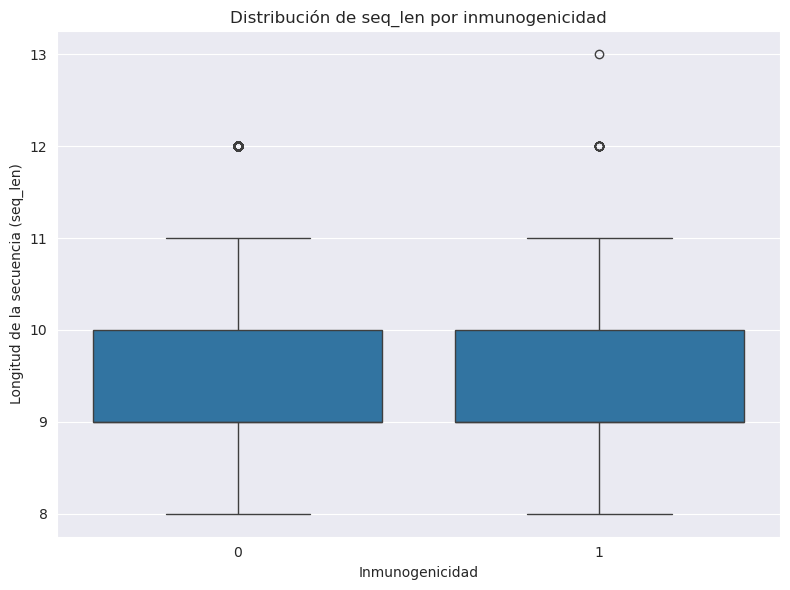

In [19]:
#Miro las seq_len entre los que son inmunogenicos y los que no
plt.figure(figsize=(8, 6))
sns.boxplot(x='immunogenicity', y='seq_len', data=df)
plt.title('Distribución de seq_len por inmunogenicidad')
plt.xlabel('Inmunogenicidad')
plt.ylabel('Longitud de la secuencia (seq_len)')
plt.tight_layout()
plt.show()


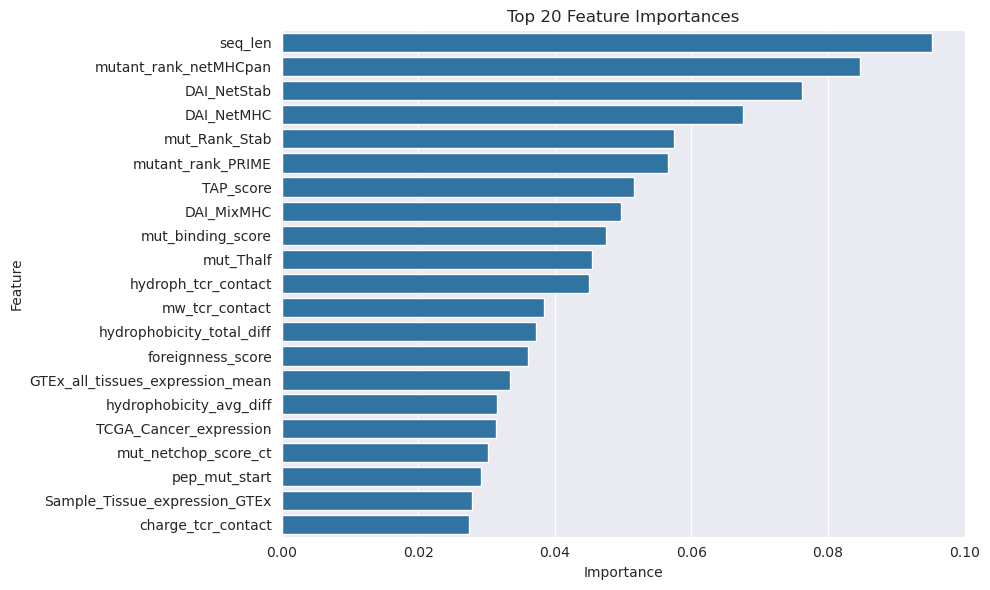

In [20]:
# Importancia de características
importances = model.feature_importances_
feature_names = X.columns
feature_importance_df = pd.DataFrame({'Feature': feature_names, 'Importance': importances})
feature_importance_df = feature_importance_df.sort_values(by='Importance', ascending=False)
# Graficar la importancia de características
plt.figure(figsize=(10, 6))
sns.barplot(x='Importance', y='Feature', data=feature_importance_df.head(25))
plt.title('Top 20 Feature Importances')
plt.tight_layout()
plt.show()

### Otras métricas

In [21]:
#G-Meassure
def g_measure(y_true, y_pred):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    if (tp + fn) == 0 or (tn + fp) == 0:
        return 0.0
    sensitivity = tp / (tp + fn)
    specificity = tn / (tn + fp)
    if (sensitivity + specificity) == 0:
        return 0.0
    g_mean = (sensitivity * specificity) ** 0.5
    return g_mean
g_measure_value = g_measure(y_test, y_pred)
print(f'G-Measure: {g_measure_value}')

G-Measure: 0.7483534795600273


In [22]:
from sklearn.metrics import jaccard_score

# Para tareas binarias
jaccard_index_value = jaccard_score(y_test, y_pred)
print(f'Jaccard Index: {jaccard_index_value}')

Jaccard Index: 0.40145985401459855


In [23]:
# Crear DataFrame temporal con predicciones
# Usamos el índice original del dataset para obtener los péptidos correspondientes
test_indices = X_test.index  # Estos son los índices originales del dataset completo
results_df = pd.DataFrame({
    'Peptide': df.loc[test_indices, 'Peptide'],  # Obtener los péptidos usando los índices del test
    'Immunogenicity': y_test.values,  # Etiquetas reales
    'score': y_pred_proba  # Probabilidades predichas
})

# Ordenar por score descendente (mayor probabilidad de ser inmunogénico primero)
results_df = results_df.sort_values('score', ascending=False)

# Mostrar los top 20
print("Top 20 péptidos con mayor probabilidad de ser inmunogénicos:")
print(results_df.head(20))

# Verificar que estamos obteniendo los datos correctos
print(f"\nVerificación:")
print(f"Número de predicciones: {len(results_df)}")
print(f"Número de péptidos únicos: {results_df['Peptide'].nunique()}")
print(f"Distribución de immunogenicidad real en el test:")
print(results_df['Immunogenicity'].value_counts())

Top 20 péptidos con mayor probabilidad de ser inmunogénicos:
          Peptide  Immunogenicity     score
8762    FSADIFFFF               1  0.991351
383     FSADIFFFF               1  0.988202
6483    GLQAILVHV               1  0.987884
5468    MLAEKTVQV               0  0.985581
3111    RTQTHATLR               1  0.985060
2807   LTLVPYTLVW               0  0.970973
9160    ALPGFFPRL               1  0.968675
6520   TLWEGGLFKL               1  0.964439
1199    YLMWLTQKV               1  0.964133
5015    FSADIFFFF               1  0.963993
7289    FSADIFFFF               1  0.963033
5328    GLLGGEYRV               1  0.962741
5436    LLNPHTLGL               1  0.961650
10415   VTNHAPLSW               0  0.960759
2757    FIMGISILL               1  0.956154
639     LYTPMYLLL               1  0.955771
11080  ILSETFQLLK               1  0.955100
6377    TADFDITEL               1  0.954116
1216    RMQYSMECF               1  0.952275
4760    TLWCSPIKV               1  0.951986

Verificación:


# Check en los si hay subgrupos en los falsos positivos

In [24]:
# Observamos los falsos positivos
false_positives = results_df[(results_df['Immunogenicity'] == 0) & (results_df['score'] >= 0.7)]
print(f"Total de falsos positivos con score >= 0.8: {len(false_positives)}")
print(false_positives)

Total de falsos positivos con score >= 0.8: 184
          Peptide  Immunogenicity     score
5468    MLAEKTVQV               0  0.985581
2807   LTLVPYTLVW               0  0.970973
10415   VTNHAPLSW               0  0.960759
7811    ALLQVTLLL               0  0.949735
2944    RYSVFFQLL               0  0.944759
...           ...             ...       ...
2606   AAYQRLTSEK               0  0.703524
3344   PSAEVEMTFY               0  0.702995
2726    GMPPCLLAL               0  0.702563
8287   LGPMGGSLTL               0  0.702074
6014    SIYFCIYFL               0  0.700349

[184 rows x 3 columns]


In [25]:
# Analizar características de los falsos positivos
fp_indices = false_positives.index
fp_features = X_test.loc[fp_indices]
fp_features['Immunogenicity'] = y_test.loc[fp_indices].values
print(fp_features.describe())

       pep_mut_start  mutant_rank_netMHCpan  mutant_rank_PRIME  mut_Rank_Stab  \
count     184.000000             184.000000         184.000000     184.000000   
mean        5.461957               0.992313           1.175761       3.707989   
std         2.902546               2.048966           2.434046       6.958642   
min         1.000000               0.001300           0.001000       0.000000   
25%         3.000000               0.105725           0.062750       0.400000   
50%         6.000000               0.359050           0.294000       1.200000   
75%         8.000000               0.972850           1.199250       3.500000   
max        12.000000              19.882400          16.716000      44.000000   

        TAP_score  mut_netchop_score_ct  mut_binding_score  DAI_NetMHC  \
count  184.000000            184.000000         184.000000  184.000000   
mean     1.123076              0.826711           2.971991   -0.977590   
std      0.949936              0.223189         

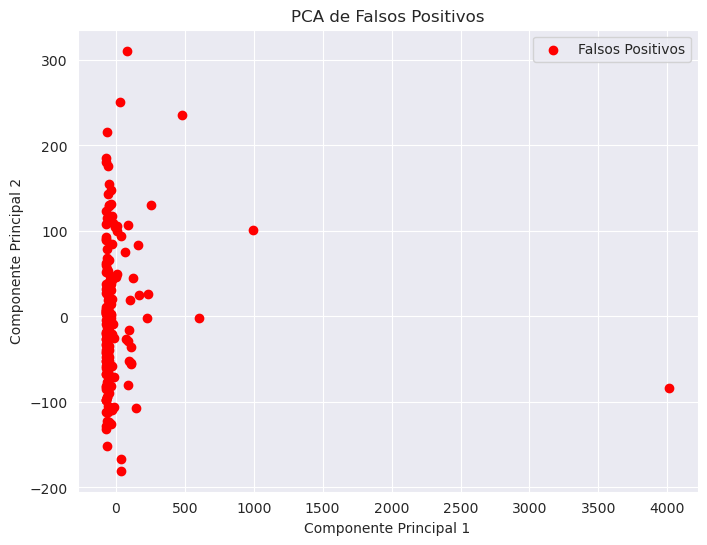

In [26]:
# Ploteamos los falsos positivos para ver si hay patrones o clusters
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
pca = PCA(n_components=2)
fp_pca = pca.fit_transform(fp_features.drop(columns=['Immunogenicity']))
plt.figure(figsize=(8, 6))
plt.scatter(fp_pca[:, 0], fp_pca[:, 1], c='red', label='Falsos Positivos')
plt.title('PCA de Falsos Positivos')
plt.xlabel('Componente Principal 1')
plt.ylabel('Componente Principal 2')
plt.legend()
plt.show()

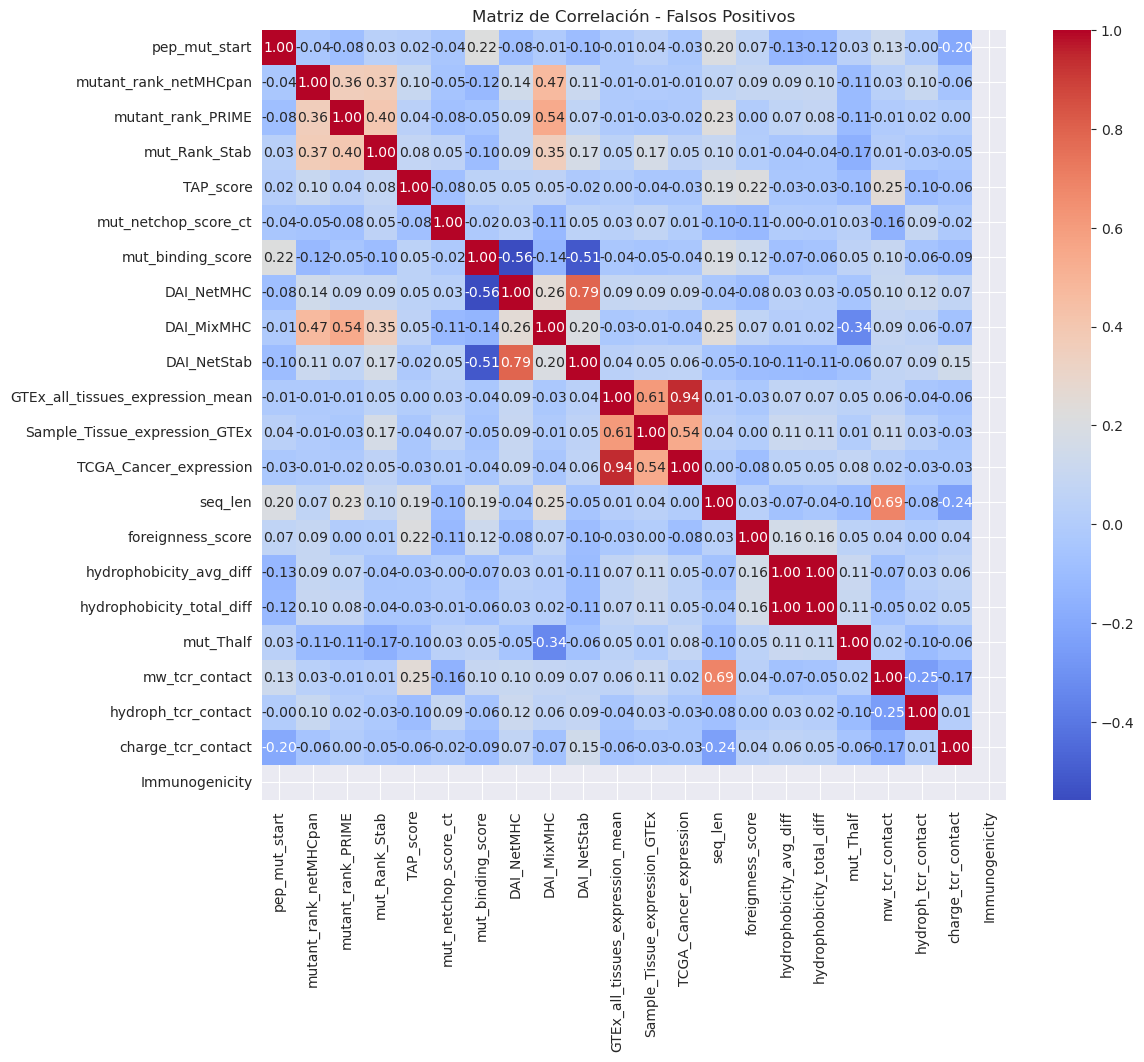

In [27]:
#Hago una matriz de correlación entre características sólo para falsos positivos
plt.figure(figsize=(12, 10))
corr_matrix = fp_features.corr()
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap='coolwarm')
plt.title('Matriz de Correlación - Falsos Positivos')
plt.show()

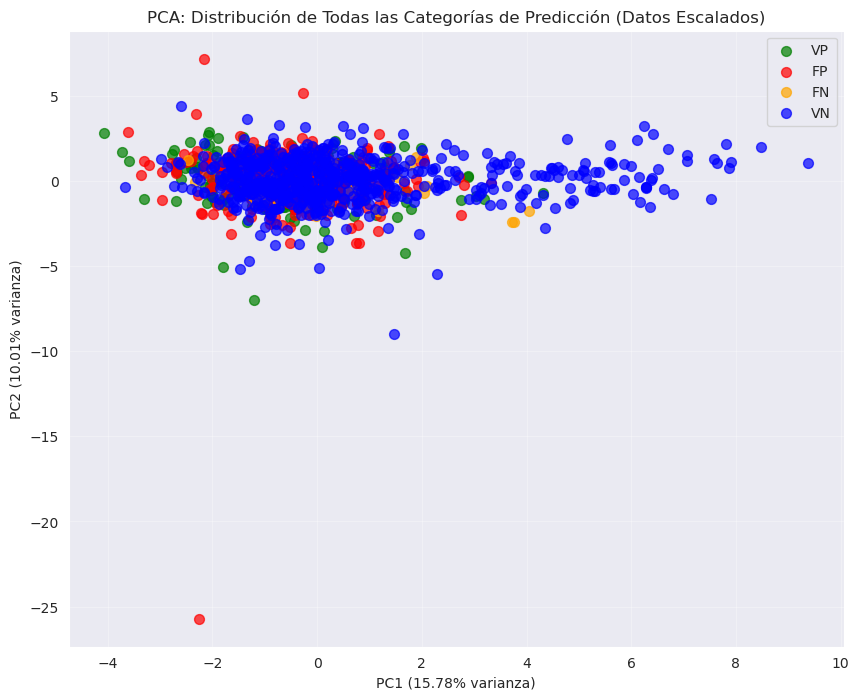

Distribución de categorías:
Category
VN    658
FP    371
VP    275
FN     39
Name: count, dtype: int64

Varianza explicada total: 25.79%

Top 5 características que más contribuyen a PC1:
                  Feature       PC1       PC2
2       mutant_rank_PRIME  0.416892  0.021623
1   mutant_rank_netMHCpan  0.414135  0.013596
8              DAI_MixMHC  0.413062  0.037929
3           mut_Rank_Stab  0.385784 -0.034242
13                seq_len  0.283433  0.236808

Top 5 características que más contribuyen a PC2:
                             Feature       PC1       PC2
16         hydrophobicity_total_diff -0.088060  0.511909
15           hydrophobicity_avg_diff -0.094573  0.506431
11     Sample_Tissue_expression_GTEx -0.028322 -0.363107
10  GTEx_all_tissues_expression_mean -0.025196 -0.354744
18                    mw_tcr_contact  0.274906  0.240682


In [28]:
# Crear dataset con todas las categorías de predicción
y_pred = model.predict(X_test)
y_pred_proba = model.predict_proba(X_test)[:, 1]

# Crear DataFrame completo con categorías
comparison_df = X_test.copy()
comparison_df['Immunogenicity_True'] = y_test
comparison_df['Immunogenicity_Pred'] = y_pred
comparison_df['Pred_Probability'] = y_pred_proba

# Clasificar predicciones
conditions = [
    (y_pred == 1) & (y_test == 1),  # Verdaderos Positivos
    (y_pred == 1) & (y_test == 0),  # Falsos Positivos
    (y_pred == 0) & (y_test == 1),  # Falsos Negativos
    (y_pred == 0) & (y_test == 0)   # Verdaderos Negativos
]
categories = ['VP', 'FP', 'FN', 'VN']
comparison_df['Category'] = np.select(conditions, categories)

# ESCALADO CRUCIAL PARA PCA
from sklearn.preprocessing import StandardScaler

# Separar features para escalar
features_to_scale = comparison_df.drop(columns=['Immunogenicity_True', 'Immunogenicity_Pred', 'Pred_Probability', 'Category'])
scaler = StandardScaler()
features_scaled = scaler.fit_transform(features_to_scale)

# PCA de todas las categorías (con datos escalados)
pca = PCA(n_components=2)
X_pca_compare = pca.fit_transform(features_scaled)

# Visualización comparativa
plt.figure(figsize=(10, 8))
colors = {'VP': 'green', 'FP': 'red', 'FN': 'orange', 'VN': 'blue'}

for category in categories:
    mask = comparison_df['Category'] == category
    plt.scatter(X_pca_compare[mask, 0], X_pca_compare[mask, 1], 
                c=colors[category], label=category, alpha=0.7, s=50)

plt.title('PCA: Distribución de Todas las Categorías de Predicción (Datos Escalados)')
plt.xlabel(f'PC1 ({pca.explained_variance_ratio_[0]:.2%} varianza)')
plt.ylabel(f'PC2 ({pca.explained_variance_ratio_[1]:.2%} varianza)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

print("Distribución de categorías:")
print(comparison_df['Category'].value_counts())
print(f"\nVarianza explicada total: {pca.explained_variance_ratio_.sum():.2%}")

# También podemos ver qué características contribuyen más a cada componente
feature_names = features_to_scale.columns
pca_components_df = pd.DataFrame({
    'Feature': feature_names,
    'PC1': pca.components_[0],
    'PC2': pca.components_[1]
})

print("\nTop 5 características que más contribuyen a PC1:")
print(pca_components_df.reindex(pca_components_df['PC1'].abs().sort_values(ascending=False).index).head(5))

print("\nTop 5 características que más contribuyen a PC2:")
print(pca_components_df.reindex(pca_components_df['PC2'].abs().sort_values(ascending=False).index).head(5))

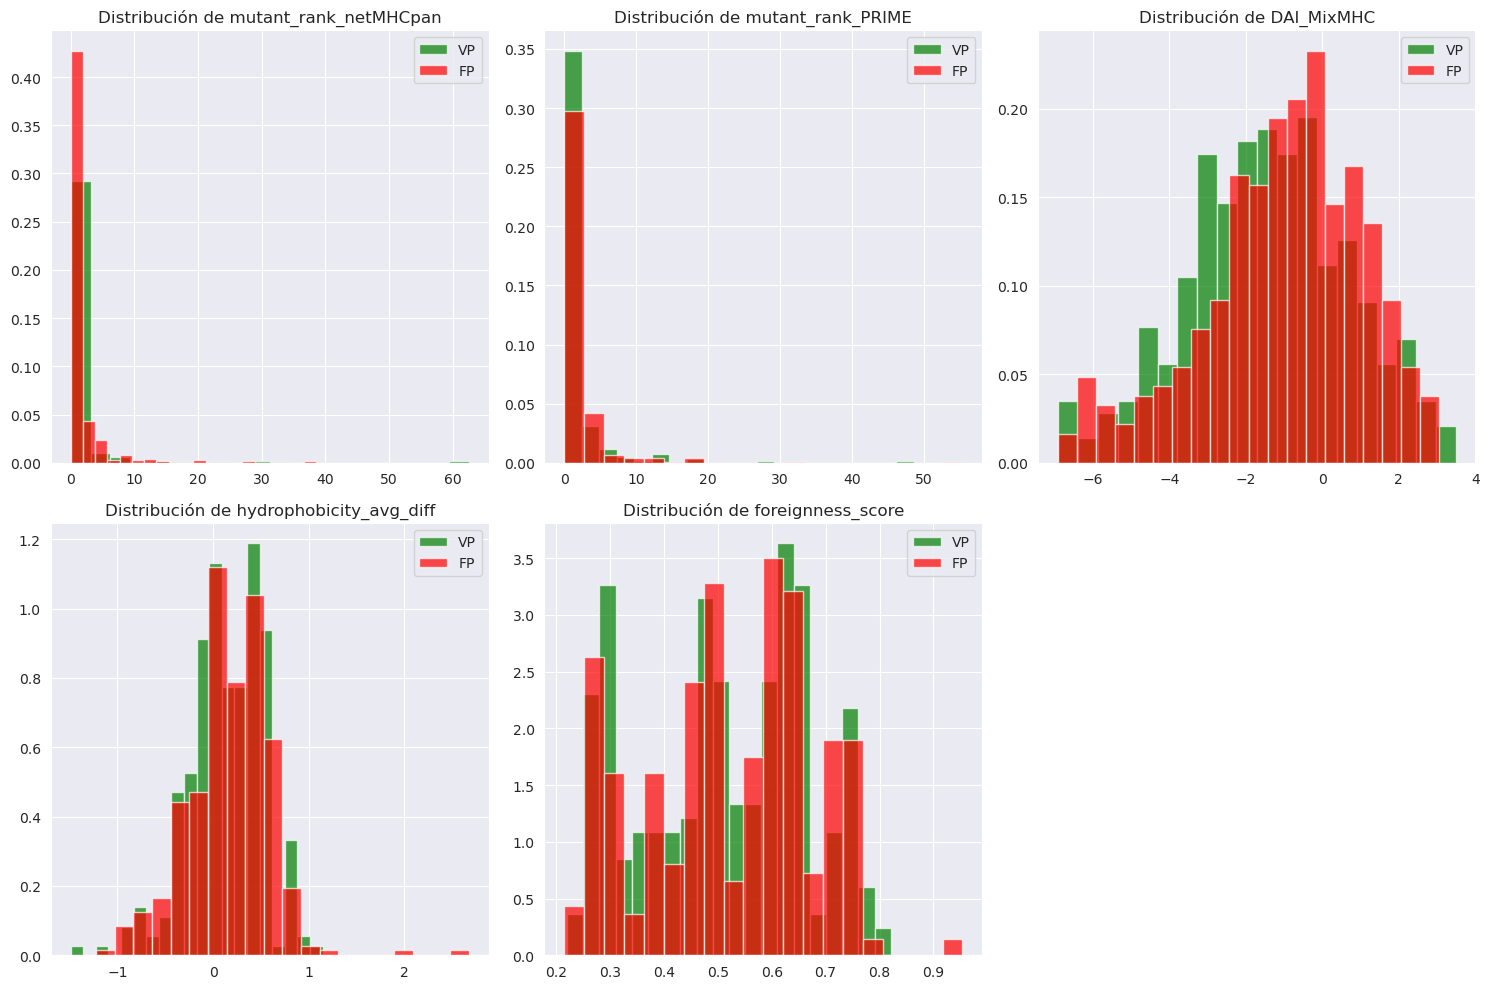

=== DIFERENCIAS MEDIAS (FP vs VP) ===
mutant_rank_netMHCpan          VP:   1.863 | FP:   1.490 | Diff:  -0.374 (-20.1%)
mutant_rank_PRIME              VP:   1.525 | FP:   1.703 | Diff:   0.177 (+11.6%)
DAI_MixMHC                     VP:  -1.422 | FP:  -1.012 | Diff:   0.410 (-28.8%)
hydrophobicity_avg_diff        VP:   0.132 | FP:   0.160 | Diff:   0.028 (+21.4%)
foreignness_score              VP:   0.513 | FP:   0.522 | Diff:   0.009 (+1.7%)

=== ANÁLISIS DE PROBABILIDADES ===
Probabilidad media VP: 0.803
Probabilidad media FP: 0.700


In [29]:
# 1. Comparar distribuciones de características clave entre VP y FP
key_features = ['mutant_rank_netMHCpan', 'mutant_rank_PRIME', 'DAI_MixMHC', 
                'hydrophobicity_avg_diff', 'foreignness_score']

plt.figure(figsize=(15, 10))
for i, feature in enumerate(key_features, 1):
    plt.subplot(2, 3, i)
    
    vp_vals = comparison_df[comparison_df['Category'] == 'VP'][feature]
    fp_vals = comparison_df[comparison_df['Category'] == 'FP'][feature]
    
    plt.hist(vp_vals, alpha=0.7, label='VP', bins=20, color='green', density=True)
    plt.hist(fp_vals, alpha=0.7, label='FP', bins=20, color='red', density=True)
    plt.title(f'Distribución de {feature}')
    plt.legend()

plt.tight_layout()
plt.show()

# 2. Análisis cuantitativo de diferencias
print("=== DIFERENCIAS MEDIAS (FP vs VP) ===")
for feature in key_features:
    vp_mean = comparison_df[comparison_df['Category'] == 'VP'][feature].mean()
    fp_mean = comparison_df[comparison_df['Category'] == 'FP'][feature].mean()
    diff = fp_mean - vp_mean
    diff_pct = (diff / vp_mean) * 100 if vp_mean != 0 else 0
    
    print(f"{feature:30} VP: {vp_mean:7.3f} | FP: {fp_mean:7.3f} | Diff: {diff:7.3f} ({diff_pct:+.1f}%)")

# 3. Análisis de probabilidades
print("\n=== ANÁLISIS DE PROBABILIDADES ===")
print(f"Probabilidad media VP: {comparison_df[comparison_df['Category'] == 'VP']['Pred_Probability'].mean():.3f}")
print(f"Probabilidad media FP: {comparison_df[comparison_df['Category'] == 'FP']['Pred_Probability'].mean():.3f}")

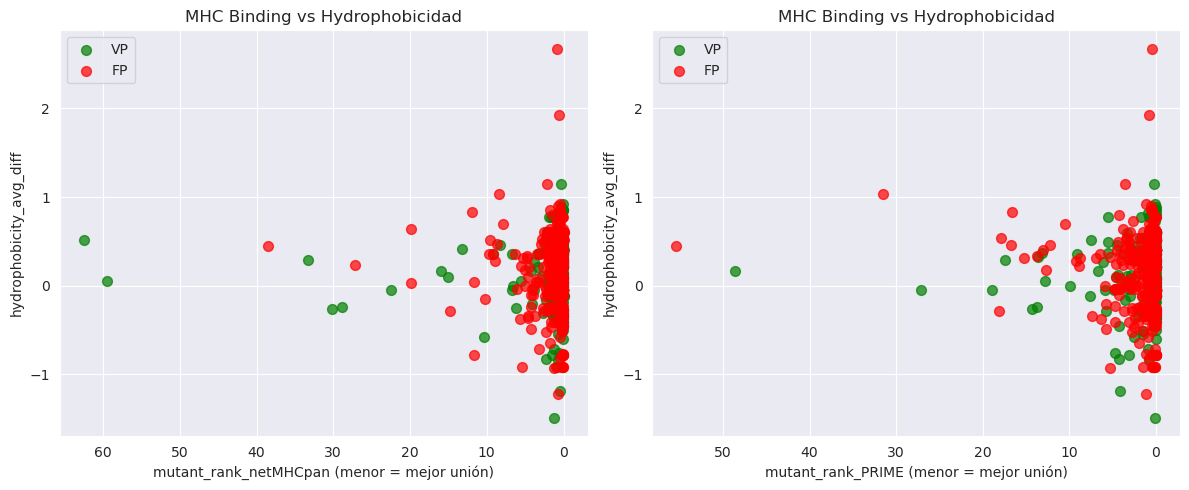

=== RANGOS ÓPTIMOS SUGERIDOS ===
Verdaderos Positivos:
  - MHC rank netMHCpan: 0.25    0.10175
0.75    1.23445
Name: mutant_rank_netMHCpan, dtype: float64
  - Hydrophobicity: 0.25   -0.05
0.75    0.40
Name: hydrophobicity_avg_diff, dtype: float64

Falsos Positivos:
  - MHC rank netMHCpan: 0.25    0.14640
0.75    1.36255
Name: mutant_rank_netMHCpan, dtype: float64
  - Hydrophobicity: 0.25   -0.0555
0.75    0.4185
Name: hydrophobicity_avg_diff, dtype: float64

Posible regla de filtrado:
  - Hydrophobicity > 0.400 → riesgo de FP
  - MHC rank < 0.102 → péptido con buena unión


In [30]:
# 1. Scatter plot: MHC binding vs Hydrophobicity
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.scatter(comparison_df[comparison_df['Category'] == 'VP']['mutant_rank_netMHCpan'], 
            comparison_df[comparison_df['Category'] == 'VP']['hydrophobicity_avg_diff'], 
            alpha=0.7, label='VP', color='green', s=50)
plt.scatter(comparison_df[comparison_df['Category'] == 'FP']['mutant_rank_netMHCpan'], 
            comparison_df[comparison_df['Category'] == 'FP']['hydrophobicity_avg_diff'], 
            alpha=0.7, label='FP', color='red', s=50)
plt.xlabel('mutant_rank_netMHCpan (menor = mejor unión)')
plt.ylabel('hydrophobicity_avg_diff')
plt.legend()
plt.title('MHC Binding vs Hydrophobicidad')
plt.gca().invert_xaxis()  # Para que mejor unión esté a la izquierda

plt.subplot(1, 2, 2)
plt.scatter(comparison_df[comparison_df['Category'] == 'VP']['mutant_rank_PRIME'], 
            comparison_df[comparison_df['Category'] == 'VP']['hydrophobicity_avg_diff'], 
            alpha=0.7, label='VP', color='green', s=50)
plt.scatter(comparison_df[comparison_df['Category'] == 'FP']['mutant_rank_PRIME'], 
            comparison_df[comparison_df['Category'] == 'FP']['hydrophobicity_avg_diff'], 
            alpha=0.7, label='FP', color='red', s=50)
plt.xlabel('mutant_rank_PRIME (menor = mejor unión)')
plt.ylabel('hydrophobicity_avg_diff')
plt.legend()
plt.title('MHC Binding vs Hydrophobicidad')
plt.gca().invert_xaxis()

plt.tight_layout()
plt.show()

# 2. Análisis de rangos óptimos
print("=== RANGOS ÓPTIMOS SUGERIDOS ===")
print("Verdaderos Positivos:")
print(f"  - MHC rank netMHCpan: {comparison_df[comparison_df['Category'] == 'VP']['mutant_rank_netMHCpan'].quantile([0.25, 0.75])}")
print(f"  - Hydrophobicity: {comparison_df[comparison_df['Category'] == 'VP']['hydrophobicity_avg_diff'].quantile([0.25, 0.75])}")

print("\nFalsos Positivos:")
print(f"  - MHC rank netMHCpan: {comparison_df[comparison_df['Category'] == 'FP']['mutant_rank_netMHCpan'].quantile([0.25, 0.75])}")
print(f"  - Hydrophobicity: {comparison_df[comparison_df['Category'] == 'FP']['hydrophobicity_avg_diff'].quantile([0.25, 0.75])}")

# 3. Regla simple para identificar FPs
hydro_threshold = comparison_df[comparison_df['Category'] == 'VP']['hydrophobicity_avg_diff'].quantile(0.75)
mhc_threshold = comparison_df[comparison_df['Category'] == 'VP']['mutant_rank_netMHCpan'].quantile(0.25)

print(f"\nPosible regla de filtrado:")
print(f"  - Hydrophobicity > {hydro_threshold:.3f} → riesgo de FP")
print(f"  - MHC rank < {mhc_threshold:.3f} → péptido con buena unión")

In [31]:
# REGLAS BASADAS EN LOS CUANTILES
HYDRO_UPPER_THRESHOLD = 0.40  # Percentil 75 de VPs
MHC_LOWER_THRESHOLD = 0.098   # Percentil 25 de VPs

def advanced_fp_filter(y_pred_proba, hydrophobicity, mhc_rank, 
                      proba_threshold=0.5, 
                      hydro_threshold=HYDRO_UPPER_THRESHOLD,
                      mhc_threshold=MHC_LOWER_THRESHOLD):
    """
    Filtro avanzado para FPs basado en el análisis de cuantiles
    """
    # Predicción inicial del modelo
    initial_pred = (y_pred_proba >= proba_threshold).astype(int)
    
    # Identificar candidatos a FP:
    # 1. Hidrofobicidad ALTA (mayor que percentil 75 de VPs)
    # 2. MHC binding MUY BUENO (mejor que percentil 25 de VPs)
    # 3. Probabilidad en rango intermedio (no demasiado alta)
    fp_risk_mask = (
        (hydrophobicity > hydro_threshold) & 
        (mhc_rank < mhc_threshold)
    )
    
    # Aplicar filtro
    final_pred = initial_pred.copy()
    final_pred[fp_risk_mask] = 0
    
    return final_pred, fp_risk_mask

# Aplicar el filtro
y_pred_filtered, fp_risk_mask = advanced_fp_filter(
    y_pred_proba,
    comparison_df['hydrophobicity_avg_diff'].values,
    comparison_df['mutant_rank_netMHCpan'].values
)

# Evaluar resultados
from sklearn.metrics import classification_report, confusion_matrix

print("=== ANTES del filtro ===")
print(classification_report(y_test, y_pred))
print(f"FPs originales: {(y_pred == 1) & (y_test == 0)}")

print("\n=== DESPUÉS del filtro ===")
print(classification_report(y_test, y_pred_filtered))
print(f"FPs después del filtro: {(y_pred_filtered == 1) & (y_test == 0)}")

# Ver cuántos FPs eliminamos
original_fps = (y_pred == 1) & (y_test == 0)
filtered_fps = (y_pred_filtered == 1) & (y_test == 0)
fps_eliminated = original_fps.sum() - filtered_fps.sum()

print(f"\nFPs eliminados: {fps_eliminated} de {original_fps.sum()} ({fps_eliminated/original_fps.sum()*100:.1f}%)")

=== ANTES del filtro ===
              precision    recall  f1-score   support

           0       0.94      0.64      0.76      1029
           1       0.43      0.88      0.57       314

    accuracy                           0.69      1343
   macro avg       0.68      0.76      0.67      1343
weighted avg       0.82      0.69      0.72      1343

FPs originales: 24       False
4815     False
10920    False
9179     False
2230     False
         ...  
2089     False
11098    False
461      False
6958      True
71       False
Name: immunogenicity, Length: 1343, dtype: bool

=== DESPUÉS del filtro ===
              precision    recall  f1-score   support

           0       0.93      0.66      0.77      1029
           1       0.43      0.83      0.56       314

    accuracy                           0.70      1343
   macro avg       0.68      0.75      0.67      1343
weighted avg       0.81      0.70      0.72      1343

FPs después del filtro: 24       False
4815     False
10920    F

### Shapley Values of every feature to reduce dimensionality

In [32]:
import shap
# Crear objeto explainer
explainer = shap.Explainer(model)
# Calcular valores SHAP
shap_values = explainer(X_test)

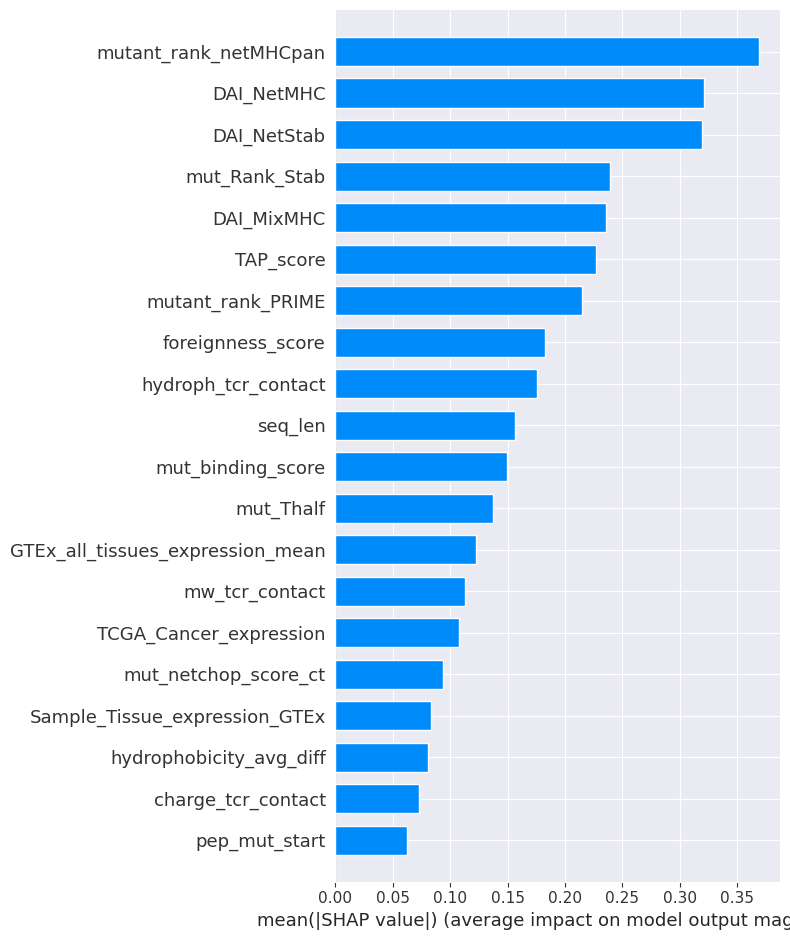

In [33]:
# Resumen de los valores SHAP
shap.summary_plot(shap_values, X_test, plot_type="bar")